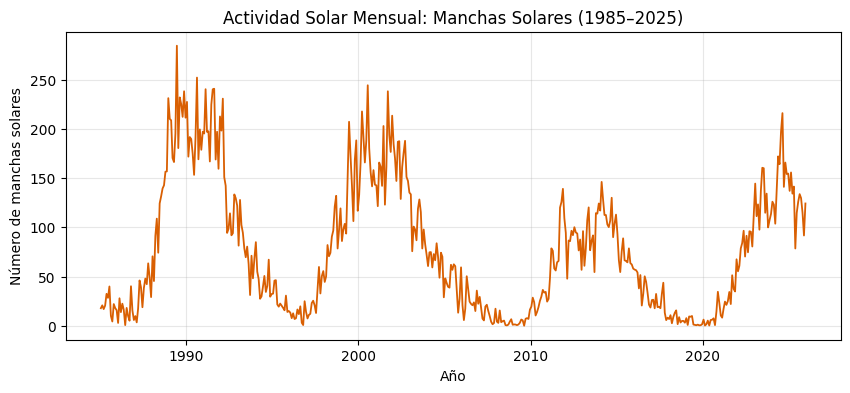

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Descargar datos oficiales de manchas solares (Observatorio Real de Bélgica)
url = "https://www.sidc.be/SILSO/DATA/SN_m_tot_V2.0.txt"
columnas = ['Anio', 'Mes', 'Fecha_dec', 'Manchas', 'Desv_est', 'Observaciones', 'Definitivo']
df_solar = pd.read_csv(url, sep=r'\s+', names=columnas)

# 2. Filtrar los últimos 40 años (1985 - 2025)
df_periodo = df_solar[(df_solar['Anio'] >= 1985) & (df_solar['Anio'] <= 2025)]

# 3. Dibujar el gráfico
plt.figure(figsize=(10, 4))
plt.plot(df_periodo['Fecha_dec'], df_periodo['Manchas'], color='#d95f02', linewidth=1.3)
plt.title('Actividad Solar Mensual: Manchas Solares (1985–2025)')
plt.xlabel('Año')
plt.ylabel('Número de manchas solares')
plt.grid(True, alpha=0.3)
plt.show()

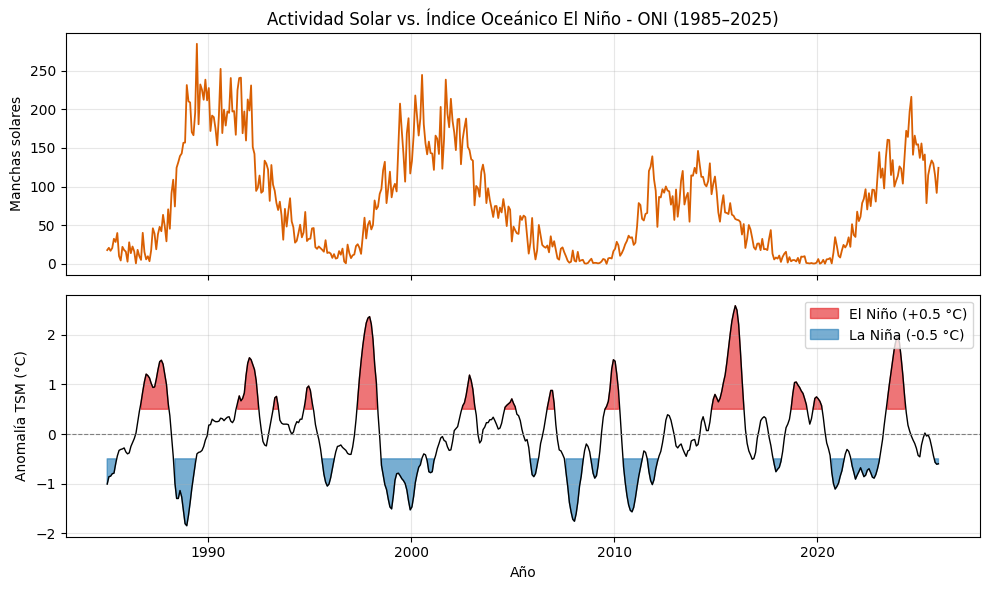

In [2]:
# 1. Descargar el Índice Oceánico El Niño (ONI) oficial de la NOAA
url_oni = "https://www.cpc.ncep.noaa.gov/data/indices/oni.ascii.txt"
df_oni = pd.read_csv(url_oni, sep=r'\s+')

# 2. Convertir las temporadas trimestrales (DJF, JFM...) a fecha decimal (1985-2025)
mapa_meses = {'DJF':1, 'JFM':2, 'FMA':3, 'MAM':4, 'AMJ':5, 'MJJ':6,
              'JJA':7, 'JAS':8, 'ASO':9, 'SON':10, 'OND':11, 'NDJ':12}
df_oni['Mes'] = df_oni['SEAS'].map(mapa_meses)
df_oni['Fecha_dec'] = df_oni['YR'] + (df_oni['Mes'] - 0.5) / 12.0
df_oni_40 = df_oni[(df_oni['YR'] >= 1985) & (df_oni['YR'] <= 2025)]

# 3. Graficar Actividad Solar vs. Eventos El Niño / La Niña
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True)

ax1.plot(df_periodo['Fecha_dec'], df_periodo['Manchas'], color='#d95f02', linewidth=1.3)
ax1.set_ylabel('Manchas solares')
ax1.set_title('Actividad Solar vs. Índice Oceánico El Niño - ONI (1985–2025)')
ax1.grid(True, alpha=0.3)

ax2.plot(df_oni_40['Fecha_dec'], df_oni_40['ANOM'], color='black', linewidth=1)
ax2.fill_between(df_oni_40['Fecha_dec'], df_oni_40['ANOM'], 0.5,
                 where=(df_oni_40['ANOM'] >= 0.5), color='#e31a1c', alpha=0.6, label='El Niño (+0.5 °C)')
ax2.fill_between(df_oni_40['Fecha_dec'], df_oni_40['ANOM'], -0.5,
                 where=(df_oni_40['ANOM'] <= -0.5), color='#1f78b4', alpha=0.6, label='La Niña (-0.5 °C)')
ax2.axhline(0, color='gray', linestyle='--', linewidth=0.8)
ax2.set_ylabel('Anomalía TSM (°C)')
ax2.set_xlabel('Año')
ax2.legend(loc='upper right')
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

/usr/local/lib/python3.13/dist-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/10m_cultural/ne_10m_admin_0_boundary_lines_land.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)
/usr/local/lib/python3.13/dist-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/10m_physical/ne_10m_coastline.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)


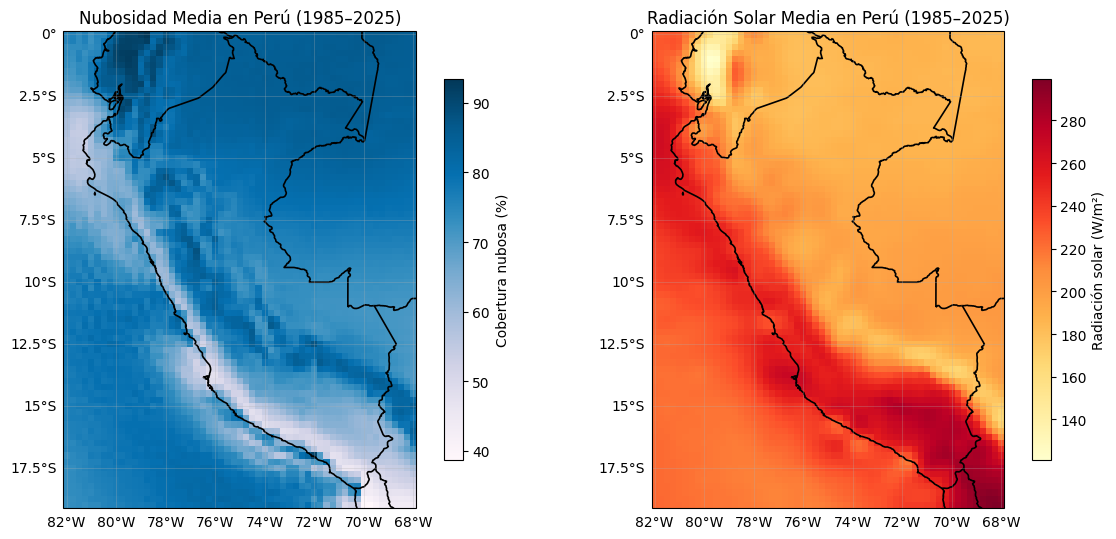

In [3]:
!pip install -q cartopy
import glob
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# 1. Leer automáticamente los dos archivos .nc del Perú
tcc = None
ssrd = None

for archivo in glob.glob('*.nc'):
    ds = xr.open_dataset(archivo)
    if 'valid_time' in ds.coords:
        ds = ds.rename({'valid_time': 'time'})
    if 'tcc' in ds.data_vars:
        tcc = ds['tcc'] * 100.0        # Convertir fracción (0-1) a porcentaje (%)
    if 'ssrd' in ds.data_vars:
        ssrd = ds['ssrd'] / 86400.0    # Convertir de J/m² diarios a W/m²

# Limpiar dimensiones extra si existen
if 'expver' in tcc.dims:
    tcc = tcc.mean(dim='expver', skipna=True)
if 'expver' in ssrd.dims:
    ssrd = ssrd.mean(dim='expver', skipna=True)

# 2. Dibujar los mapas promedio de 40 años (1985-2025) sobre el Perú
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5.5),
                               subplot_kw={'projection': ccrs.PlateCarree()})

# Mapa 1: Nubosidad Total (%)
tcc.mean(dim='time').plot(ax=ax1, transform=ccrs.PlateCarree(), cmap='PuBu',
                          cbar_kwargs={'label': 'Cobertura nubosa (%)', 'shrink': 0.8})
ax1.add_feature(cfeature.BORDERS, linewidth=1.2, edgecolor='black')
ax1.add_feature(cfeature.COASTLINE, linewidth=1.2, edgecolor='black')
gl1 = ax1.gridlines(draw_labels=True, linewidth=0.5, alpha=0.4)
gl1.top_labels = False
gl1.right_labels = False
ax1.set_title('Nubosidad Media en Perú (1985–2025)')

# Mapa 2: Radiación Solar Superficial (W/m²)
ssrd.mean(dim='time').plot(ax=ax2, transform=ccrs.PlateCarree(), cmap='YlOrRd',
                           cbar_kwargs={'label': 'Radiación solar (W/m²)', 'shrink': 0.8})
ax2.add_feature(cfeature.BORDERS, linewidth=1.2, edgecolor='black')
ax2.add_feature(cfeature.COASTLINE, linewidth=1.2, edgecolor='black')
gl2 = ax2.gridlines(draw_labels=True, linewidth=0.5, alpha=0.4)
gl2.top_labels = False
gl2.right_labels = False
ax2.set_title('Radiación Solar Media en Perú (1985–2025)')

plt.tight_layout()
plt.show()

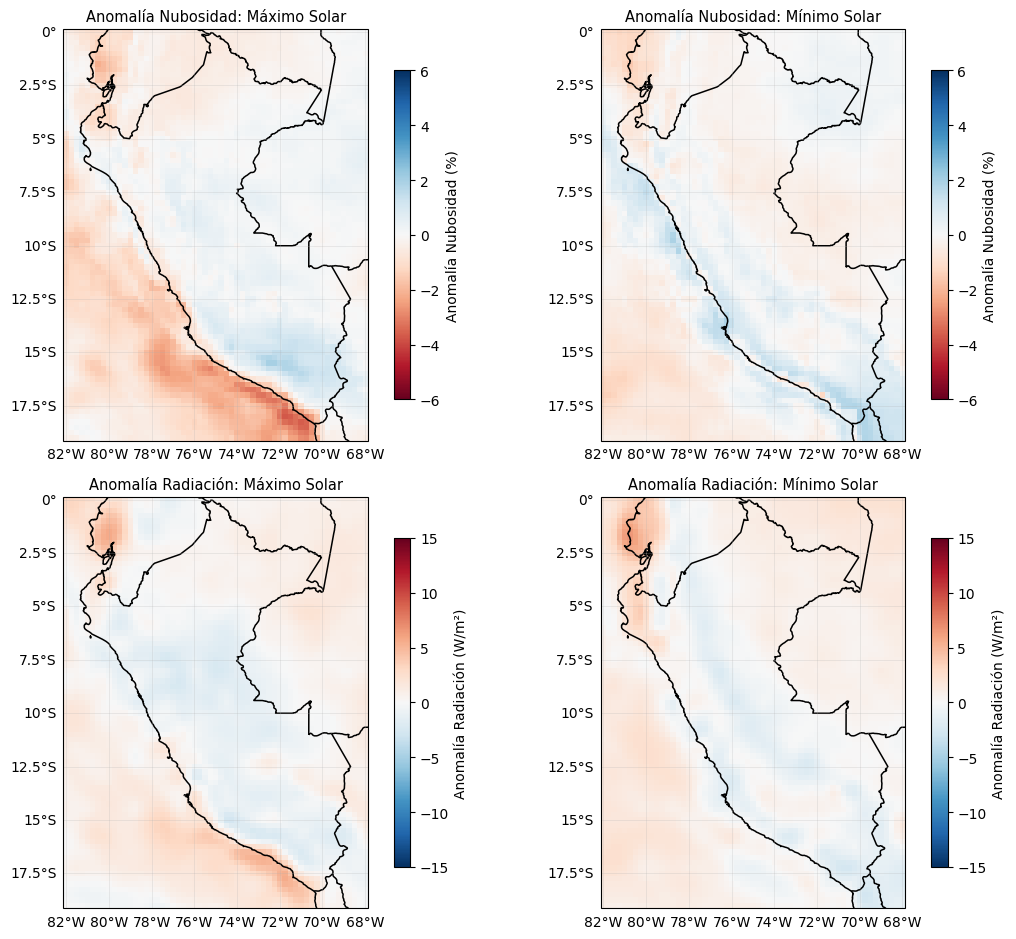

In [4]:
# 1. Calcular anomalías mensuales respecto al periodo base 1991-2020
clim_tcc = tcc.sel(time=slice('1991-01-01', '2020-12-31')).groupby('time.month').mean('time')
anom_tcc = tcc.groupby('time.month') - clim_tcc

clim_ssrd = ssrd.sel(time=slice('1991-01-01', '2020-12-31')).groupby('time.month').mean('time')
anom_ssrd = ssrd.groupby('time.month') - clim_ssrd

# 2. Vincular cada mes del mapa con el número de manchas solares (SILSO)
mapa_sol = dict(zip(zip(df_periodo['Anio'], df_periodo['Mes']), df_periodo['Manchas']))
manchas_mes = [mapa_sol.get((int(y), int(m)), float('nan'))
               for y, m in zip(anom_tcc.time.dt.year.values, anom_tcc.time.dt.month.values)]

anom_tcc = anom_tcc.assign_coords(manchas=('time', manchas_mes))
anom_ssrd = anom_ssrd.assign_coords(manchas=('time', manchas_mes))

# 3. Promediar anomalías en Máximos Solares (>=120) vs. Mínimos Solares (<=25)
tcc_max = anom_tcc.where(anom_tcc.manchas >= 120, drop=True).mean('time')
tcc_min = anom_tcc.where(anom_tcc.manchas <= 25, drop=True).mean('time')
ssrd_max = anom_ssrd.where(anom_ssrd.manchas >= 120, drop=True).mean('time')
ssrd_min = anom_ssrd.where(anom_ssrd.manchas <= 25, drop=True).mean('time')

# 4. Graficar panel comparativo de 4 mapas (2x2)
fig, axes = plt.subplots(2, 2, figsize=(11, 9.5), subplot_kw={'projection': ccrs.PlateCarree()})

escenarios = [
    (axes[0, 0], tcc_max, 'RdBu', -6, 6, 'Anomalía Nubosidad (%)', 'Anomalía Nubosidad: Máximo Solar'),
    (axes[0, 1], tcc_min, 'RdBu', -6, 6, 'Anomalía Nubosidad (%)', 'Anomalía Nubosidad: Mínimo Solar'),
    (axes[1, 0], ssrd_max, 'RdBu_r', -15, 15, 'Anomalía Radiación (W/m²)', 'Anomalía Radiación: Máximo Solar'),
    (axes[1, 1], ssrd_min, 'RdBu_r', -15, 15, 'Anomalía Radiación (W/m²)', 'Anomalía Radiación: Mínimo Solar')
]

for ax, data, cmap, vmin, vmax, label, title in escenarios:
    data.plot(ax=ax, transform=ccrs.PlateCarree(), cmap=cmap, vmin=vmin, vmax=vmax,
              cbar_kwargs={'label': label, 'shrink': 0.8})
    ax.add_feature(cfeature.BORDERS, linewidth=1.1, edgecolor='black')
    ax.add_feature(cfeature.COASTLINE, linewidth=1.1, edgecolor='black')
    gl = ax.gridlines(draw_labels=True, linewidth=0.4, alpha=0.4)
    gl.top_labels = False
    gl.right_labels = False
    ax.set_title(title, fontsize=10.5)

plt.tight_layout()
plt.show()

=== RESULTADOS ESTADÍSTICOS (1985–2025) ===

Serie Completa (n=492):
  - Manchas Solares vs. Nubes Costa:     r = -0.054 (p = 0.2329)
  - Manchas Solares vs. Radiación Costa: r = 0.034 (p = 0.4577)

Solo Fase Neutra sin ENSO (n=235):
  - Manchas Solares vs. Nubes Costa:     r = 0.016 (p = 0.8113)
  - Manchas Solares vs. Radiación Costa: r = -0.001 (p = 0.9880)

Control ENSO (ONI vs. Nubes Costa):      r = -0.158 (p = 0.0004)


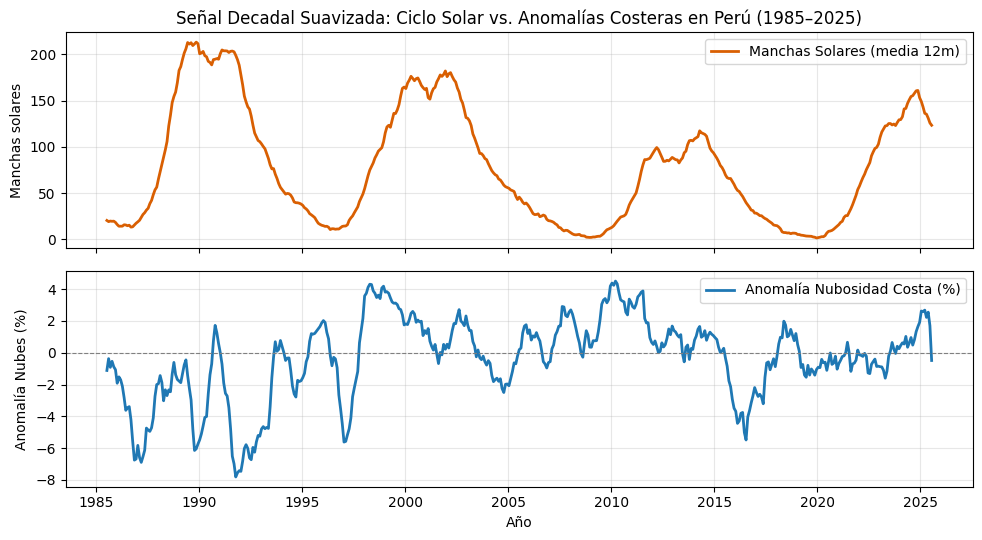

In [5]:
import pandas as pd
import numpy as np
from scipy.stats import pearsonr

# 1. Detectar nombres de coordenadas y extraer promedios regionales
lat_c = 'latitude' if 'latitude' in anom_tcc.coords else 'lat'
lon_c = 'longitude' if 'longitude' in anom_tcc.coords else 'lon'

# Región A: Franja Costera Centro-Sur (10°S a 18°S, 81°W a 75°W)
costa_tcc = anom_tcc.sel({lat_c: slice(-10, -18), lon_c: slice(-81, -75)}).mean(dim=[lat_c, lon_c])
costa_ssrd = anom_ssrd.sel({lat_c: slice(-10, -18), lon_c: slice(-81, -75)}).mean(dim=[lat_c, lon_c])

# Región B: Andes Centro-Sur (10°S a 18°S, 75°W a 69°W)
andes_tcc = anom_tcc.sel({lat_c: slice(-10, -18), lon_c: slice(-75, -69)}).mean(dim=[lat_c, lon_c])

# 2. Unir todo en una sola tabla mensual (1985-2025)
df_analisis = pd.DataFrame({
    'Anio': anom_tcc.time.dt.year.values,
    'Mes': anom_tcc.time.dt.month.values,
    'Manchas': anom_tcc.manchas.values,
    'Anom_Nubes_Costa': costa_tcc.values,
    'Anom_Rad_Costa': costa_ssrd.values,
    'Anom_Nubes_Andes': andes_tcc.values
})

df_analisis = df_analisis.merge(df_oni_40[['YR', 'Mes', 'ANOM']], left_on=['Anio', 'Mes'], right_on=['YR', 'Mes']).dropna()
df_analisis.rename(columns={'ANOM': 'ONI'}, inplace=True)

# 3. Calcular correlaciones (Todos los meses vs. Solo meses neutros sin ENSO)
df_neutro = df_analisis[df_analisis['ONI'].abs() < 0.5]

print("=== RESULTADOS ESTADÍSTICOS (1985–2025) ===")
for nombre, sub in [("Serie Completa (n=" + str(len(df_analisis)) + ")", df_analisis),
                    ("Solo Fase Neutra sin ENSO (n=" + str(len(df_neutro)) + ")", df_neutro)]:
    r_nubes, p_nubes = pearsonr(sub['Manchas'], sub['Anom_Nubes_Costa'])
    r_rad, p_rad = pearsonr(sub['Manchas'], sub['Anom_Rad_Costa'])
    print(f"\n{nombre}:")
    print(f"  - Manchas Solares vs. Nubes Costa:     r = {r_nubes:.3f} (p = {p_nubes:.4f})")
    print(f"  - Manchas Solares vs. Radiación Costa: r = {r_rad:.3f} (p = {p_rad:.4f})")

r_enso, p_enso = pearsonr(df_analisis['ONI'], df_analisis['Anom_Nubes_Costa'])
print(f"\nControl ENSO (ONI vs. Nubes Costa):      r = {r_enso:.3f} (p = {p_enso:.4f})")

# 4. Graficar series suavizadas (media móvil de 12 meses) para ver la tendencia decadal
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 5.5), sharex=True)
fechas = df_analisis['Anio'] + (df_analisis['Mes'] - 0.5) / 12.0

ax1.plot(fechas, df_analisis['Manchas'].rolling(12, center=True).mean(), color='#d95f02', lw=2, label='Manchas Solares (media 12m)')
ax1.set_ylabel('Manchas solares')
ax1.set_title('Señal Decadal Suavizada: Ciclo Solar vs. Anomalías Costeras en Perú (1985–2025)')
ax1.legend(loc='upper right')
ax1.grid(True, alpha=0.3)

ax2.plot(fechas, df_analisis['Anom_Nubes_Costa'].rolling(12, center=True).mean(), color='#1f78b4', lw=2, label='Anomalía Nubosidad Costa (%)')
ax2.axhline(0, color='gray', linestyle='--', lw=0.8)
ax2.set_ylabel('Anomalía Nubes (%)')
ax2.set_xlabel('Año')
ax2.legend(loc='upper right')
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()